In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import os
for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        print(os.path.join(root, f))

/kaggle/input/datasets/mlg-ulb/creditcardfraud/creditcard.csv


In [3]:
import pandas as pd

# Read the CSV into a table (DataFrame)
df = pd.read_csv("/kaggle/input/datasets/mlg-ulb/creditcardfraud/creditcard.csv")

# Rows and columns
print("Shape:", df.shape)

# Count normal (0) vs fraud (1)
print(df["Class"].value_counts())

# Fraud as a % of all transactions
print("Fraud %:", round(df["Class"].mean() * 100, 3))

Shape: (284807, 31)
Class
0    284315
1       492
Name: count, dtype: int64
Fraud %: 0.173


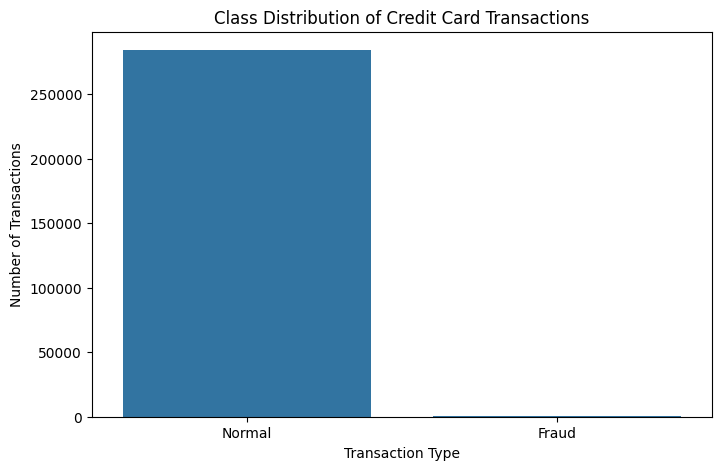

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count normal and fraudulent transactions
class_counts = df["Class"].value_counts()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=["Normal", "Fraud"],
    y=[class_counts[0], class_counts[1]]
)

plt.title("Class Distribution of Credit Card Transactions")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")

plt.savefig(
    "/kaggle/working/01_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Finding:** The dataset contains 284,315 normal transactions and only 492 fraudulent transactions. Fraud accounts for just 0.173% of all transactions, showing a severe class imbalance. Therefore, accuracy alone will not be a reliable evaluation metric for our models.

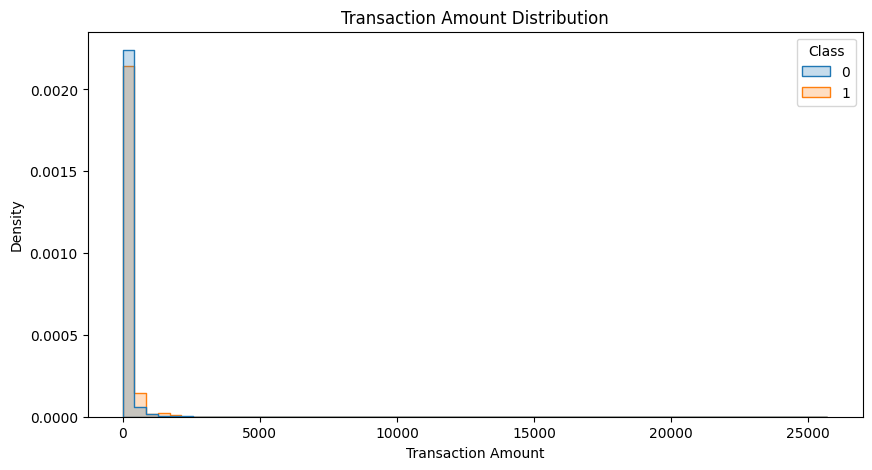

In [5]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Amount",
    hue="Class",
    bins=60,
    stat="density",
    common_norm=False,
    element="step"
)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Density")

plt.savefig(
    "/kaggle/working/02_amount_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

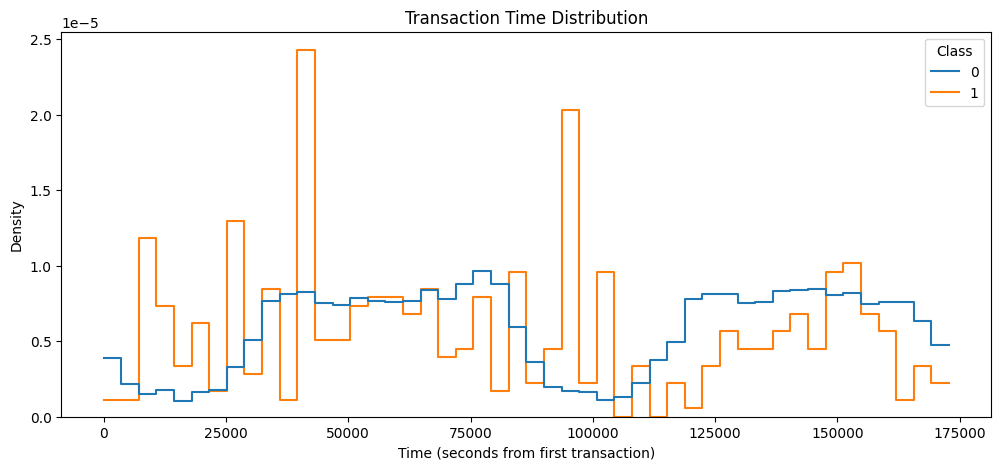

In [6]:

plt.figure(figsize=(12, 5))

sns.histplot(
    data=df,
    x="Time",
    hue="Class",
    bins=48,
    stat="density",
    common_norm=False,
    element="step",
    fill=False
)

plt.title("Transaction Time Distribution")
plt.xlabel("Time (seconds from first transaction)")
plt.ylabel("Density")

plt.savefig(
    "/kaggle/working/03_time_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [7]:

print("AMOUNT STATISTICS")

print(
    df.groupby("Class")["Amount"].agg(
        ["count", "mean", "median", "std", "min", "max"]
    ).round(2)
)

print("\nTIME STATISTICS")

print(
    df.groupby("Class")["Time"].agg(
        ["count", "mean", "median", "min", "max"]
    ).round(2)
)

print("\nFRAUD PERCENTAGE")

print(f"{df['Class'].mean() * 100:.4f}%")


AMOUNT STATISTICS
        count    mean  median     std  min       max
Class                                               
0      284315   88.29   22.00  250.11  0.0  25691.16
1         492  122.21    9.25  256.68  0.0   2125.87

TIME STATISTICS
        count      mean   median    min       max
Class                                            
0      284315  94838.20  84711.0    0.0  172792.0
1         492  80746.81  75568.5  406.0  170348.0

FRAUD PERCENTAGE
0.1727%


## Exploratory Data Analysis – Findings

### 1. Class Distribution
The dataset contains 284,807 transactions, including 284,315 normal transactions and 492 fraudulent transactions. Fraud represents approximately 0.1727% of all transactions, indicating severe class imbalance.

### 2. Transaction Amount
Normal transactions have a mean amount of 88.29 and a median of 22.00, while fraudulent transactions have a mean of 122.21 and a median of 9.25. The difference between mean and median suggests skewness in transaction amounts. A few large transactions influence the average.

### 3. Transaction Time
Normal transactions have an average elapsed time of 94,838.20 seconds, compared with 80,746.81 seconds for fraudulent transactions. The median transaction times are 84,711 and 75,568.5 seconds, respectively. The distributions show some differences, but time alone cannot reliably identify fraud.

### 4. Overall Observation
The dataset presents a challenging fraud detection problem because fraudulent transactions account for only 0.1727% of all records. Amount and time show differences between the two classes, but further machine learning analysis is required. Therefore, precision, recall, F1-score and PR-AUC will be important evaluation metrics.

In [8]:
import zipfile
import os

figure_files = [
    "/kaggle/working/01_class_distribution.png",
    "/kaggle/working/02_amount_distribution.png",
    "/kaggle/working/03_time_distribution.png"
]

with zipfile.ZipFile(
    "/kaggle/working/eda_charts.zip", "w"
) as zip_file:

    for file in figure_files:
        if os.path.exists(file):
            zip_file.write(file, os.path.basename(file))

print("EDA charts packaged successfully!")

EDA charts packaged successfully!
